# Chapter 14: The Karlin–Rubin Theorem and UMP Tests

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch14/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/izupress/statistical-theory/blob/main/notebooks/ch_14.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## The Exponential Rate Test: Simulation and Exact Power

*Source file:* `code/ch14/c14_1_exponential_rate_test_exact_power.py`

In [2]:
import numpy as np
import scipy.stats as stats

rng = np.random.default_rng(42)
c = stats.chi2.ppf(0.05, df=20) / 2.0
samples = rng.exponential(scale=1.0/1.5, size=(100_000, 10))
print(f"theta=1.5 power: {np.mean(np.sum(samples, axis=1) < c):.4f}")
print(f"Critical value c = {c:.4f} | exact power = P(chi2_20 < 3c) = {stats.chi2.cdf(1.5*2*c, 20):.4f}")
h0 = rng.exponential(scale=1.0, size=(100_000, 10))
print(f"rejection rate at theta=1.0 (size): {np.mean(h0.sum(axis=1) < c):.4f}")
for th in [0.5, 0.8, 1.0, 1.5, 2.0, 3.0]:
    print(f"  beta({th:.1f}) = {stats.chi2.cdf(2*th*c, 20):.4f}")

theta=1.5 power: 0.3003
Critical value c = 5.4254 | exact power = P(chi2_20 < 3c) = 0.3007
rejection rate at theta=1.0 (size): 0.0512
  beta(0.5) = 0.0005
  beta(0.8) = 0.0137
  beta(1.0) = 0.0500
  beta(1.5) = 0.3007
  beta(2.0) = 0.6431
  beta(3.0) = 0.9622


## The Two-Sided Problem: One-Sided Tests Cannot Be UMP

*Source file:* `code/ch14/c14_2_two_sided_problem_one_sided_tests.py`

mu-mu0=-0.4 | upper=0.000 | lower=0.639 | two-sided=0.516
mu-mu0=+0.2 | upper=0.260 | lower=0.004 | two-sided=0.170
mu-mu0=+0.4 | upper=0.639 | lower=0.000 | two-sided=0.516


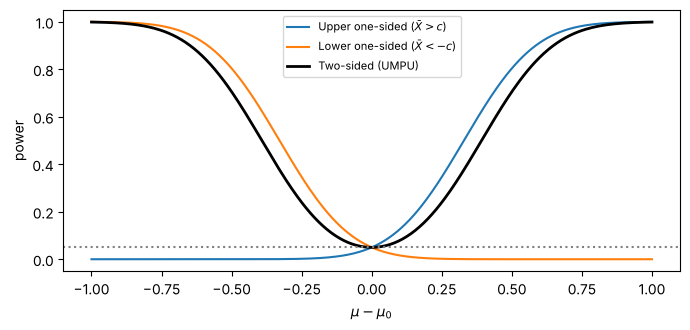

In [3]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

sigma, n, a = 1.0, 25, 0.05
d = np.linspace(-1, 1, 401) * np.sqrt(n) / sigma        # sqrt(n)(mu - mu0)/sigma
za, za2 = stats.norm.ppf(1 - a), stats.norm.ppf(1 - a/2)
upp  = 1 - stats.norm.cdf(za - d)
low  = stats.norm.cdf(-za - d)
two  = 1 - stats.norm.cdf(za2 - d) + stats.norm.cdf(-za2 - d)
fig, ax = plt.subplots(figsize=(7, 3.4))
mu = d * sigma / np.sqrt(n)
ax.plot(mu, upp, label="Upper one-sided ($\\bar X > c$)")
ax.plot(mu, low, label="Lower one-sided ($\\bar X < -c$)")
ax.plot(mu, two, "k", lw=2, label="Two-sided (UMPU)")
ax.axhline(a, color="gray", ls=":"); ax.set_xlabel(r"$\mu-\mu_0$"); ax.set_ylabel("power"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("iki_tarafli.pdf")
for m in [-0.4, 0.2, 0.4]:
    k = np.argmin(np.abs(mu - m))
    print(f"mu-mu0={m:+.1f} | upper={upp[k]:.3f} | lower={low[k]:.3f} | two-sided={two[k]:.3f}")

## Uniform: MLR and the Power of the UMP Test

*Source file:* `code/ch14/c14_3_uniform_mlr_ump_power.py`

In [4]:
import numpy as np

rng = np.random.default_rng(42)
theta0, n, a, R = 1.0, 8, 0.05, 200_000
c = theta0 * (1 - a)**(1/n)
for th in [0.9, 1.0, 1.1, 1.3]:
    M = rng.uniform(0, th, size=(R, n)).max(axis=1)
    theory = max(0.0, 1 - (1 - a)*(theta0/th)**n) if th > theta0 else (1 - (c/th)**n if c < th else 0.0)
    print(f"theta={th:.1f} | rejection rate={np.mean(M > c):.4f} | theory={theory:.4f}")

theta=0.9 | rejection rate=0.0000 | theory=0.0000


theta=1.0 | rejection rate=0.0505 | theory=0.0500
theta=1.1 | rejection rate=0.5587 | theory=0.5568
theta=1.3 | rejection rate=0.8836 | theory=0.8835
